In [1]:
import os
import utils
import pickle
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from utils import summary, train
from collections import OrderedDict

# Parametri

In [2]:
os.makedirs("histories", exist_ok=True)

EPOCHS = 10
BATCH_SIZE = 256
LEARNING_RATE = 0.001
DEVICE = torch.accelerator.current_accelerator() if torch.accelerator.is_available() else torch.DEVICE('cpu')

print(f"DEVICE: {DEVICE}")

DEVICE: cuda


# Dataset

TRAIN SET shape: torch.Size([60000, 28, 28])
TEST SET shape:  torch.Size([10000, 28, 28])


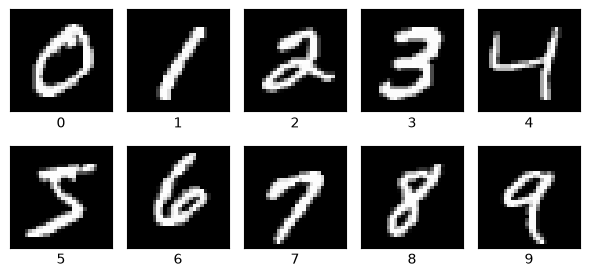

In [3]:
from datasets.datasets import load_MNIST
train_dataset, test_dataset, train_loader, test_loader = load_MNIST(batch_size=BATCH_SIZE, verbose=False)

print(f"TRAIN SET shape: {train_dataset.data.shape}")
print(f"TEST SET shape:  {test_dataset.data.shape}")

plt.figure(figsize=(6, 3))
for c in range(len(train_dataset.classes)):
    idx = (train_dataset.targets == c).nonzero()[0].item()   # primo esempio della classe c
    img, label = train_dataset[idx]
    plt.subplot(2, 5, c + 1)
    plt.xticks([])
    plt.yticks([])
    plt.imshow(img.squeeze(), cmap="gray")
    plt.xlabel(label)
plt.tight_layout()
plt.show()

# Modello

In [4]:
model_conv = nn.Sequential(OrderedDict([
    ('conv2d', nn.Conv2d(1, 32, kernel_size=3)), ('relu', nn.ReLU()),
    ('max_pooling2d', nn.MaxPool2d(2)),
    ('conv2d_1', nn.Conv2d(32, 64, kernel_size=3)), ('relu_1', nn.ReLU()),
    ('max_pooling2d_1', nn.MaxPool2d(2)),
    ('conv2d_2', nn.Conv2d(64, 64, kernel_size=3)), ('relu_2', nn.ReLU()),
    ('flatten', nn.Flatten()),
    ('dropout', nn.Dropout(0.5)),
    ('dense', nn.LazyLinear(64)), ('relu_3', nn.ReLU()),
    ('dense_1', nn.Linear(64, 10))
])).to(DEVICE)

loss_fn = nn.CrossEntropyLoss() 
optimizer_conv = torch.optim.Adam(model_conv.parameters(), lr=1e-3)
summary(model_conv, (1, 28, 28))

Layer (type)                Output Shape               Param #
conv2d (Conv2d)             (None, 32, 26, 26)             320
relu (ReLU)                 (None, 32, 26, 26)               0
max_pooling2d (MaxPool2d)   (None, 32, 13, 13)               0
conv2d_1 (Conv2d)           (None, 64, 11, 11)          18,496
relu_1 (ReLU)               (None, 64, 11, 11)               0
max_pooling2d_1 (MaxPool2d) (None, 64, 5, 5)                 0
conv2d_2 (Conv2d)           (None, 64, 3, 3)            36,928
relu_2 (ReLU)               (None, 64, 3, 3)                 0
flatten (Flatten)           (None, 576)                      0
dropout (Dropout)           (None, 576)                      0
dense (Linear)              (None, 64)                  36,928
relu_3 (ReLU)               (None, 64)                       0
dense_1 (Linear)            (None, 10)                     650
Total params: 93,322
Trainable params: 93,322
Non-trainable params: 0


# Addestramento

  0%|          | 0/10 [00:00<?, ?it/s]

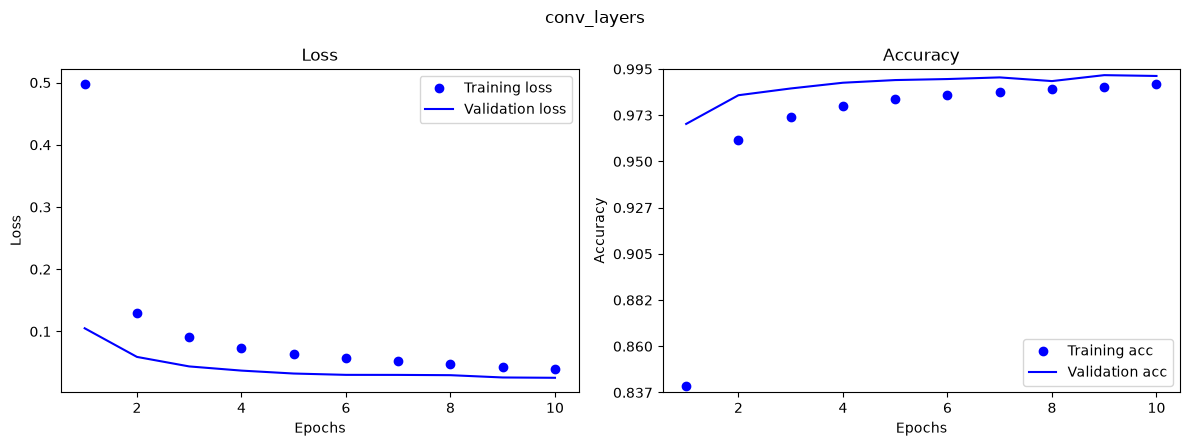

In [5]:
name = "conv_layers"

exists = os.path.isfile(f'histories/{name}.hist') and os.path.isfile(f'histories/{name}.pt')
if 0:
    with open(f'histories/{name}.hist','rb') as hist_file:
        history_dict = pickle.load(hist_file)
    model_conv.load_state_dict(torch.load(f'histories/{name}.pt', map_location=device))
else:
    history_dict = utils.train(model_conv, optimizer_conv, loss_fn, train_loader, test_loader, epochs=EPOCHS, device=DEVICE)
    with open(f'histories/{name}.hist','wb') as hist_file:
        pickle.dump(history_dict, hist_file)
    torch.save(model_conv.state_dict(), f'histories/{name}.pt')
    
utils.hist_plot(history_dict, name)

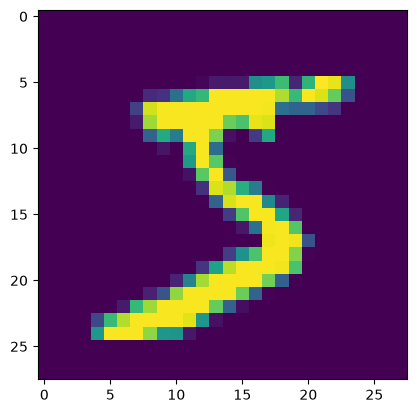

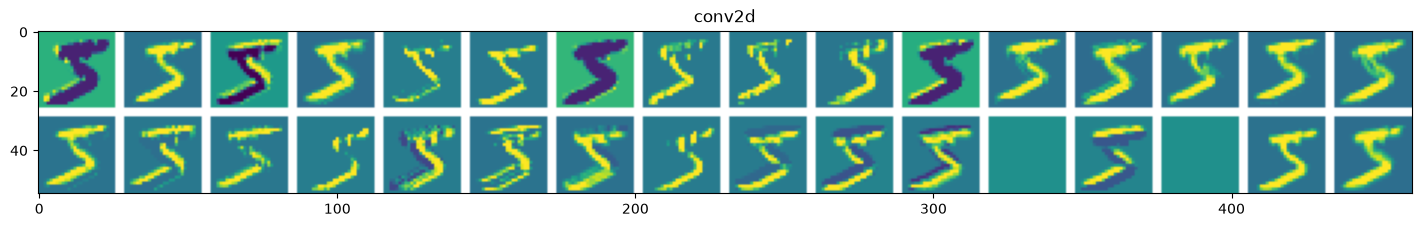

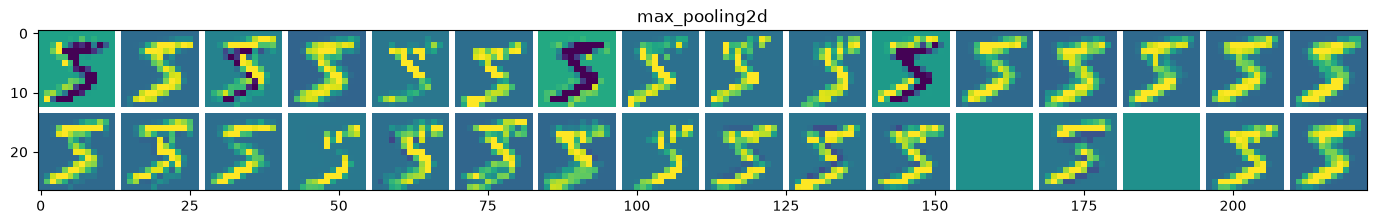

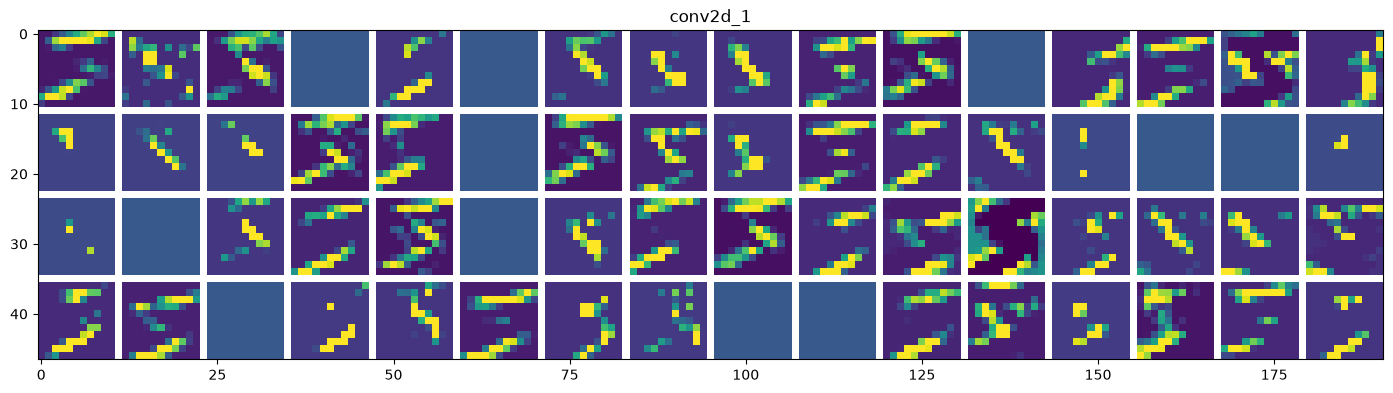

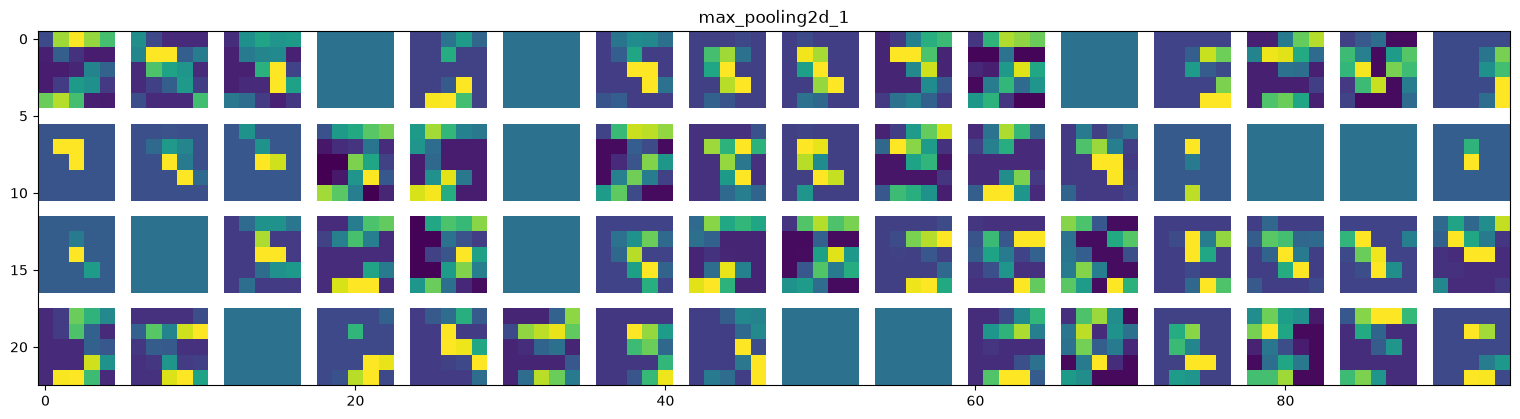

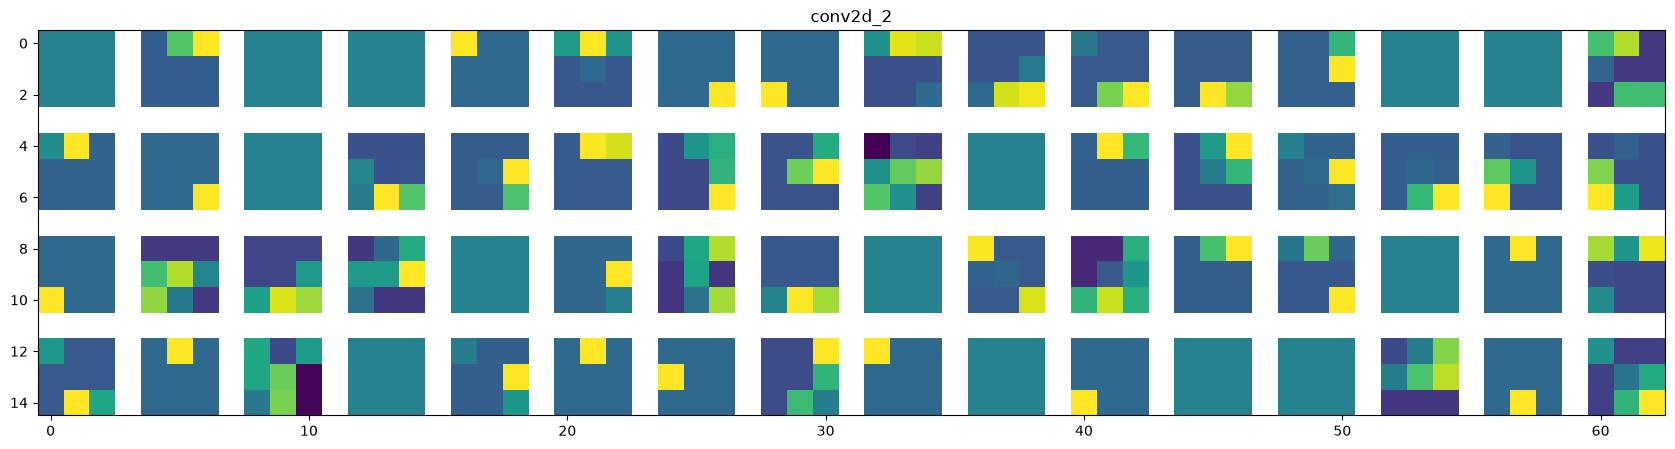

In [9]:
img = train_dataset[0][0]

plt.figure()
plt.imshow(img.permute((1,2,0)), cmap='viridis')
img = torch.as_tensor(img.reshape((1,1,28,28)), dtype=torch.float32, device=DEVICE)

# attivazioni dei primi 5 layer (conv, pool, conv, pool, conv), ciascuna con il proprio nome
model_conv.eval()
activations, layer_names = [], []
x = img
with torch.no_grad():
    for layer_name, layer in model_conv.named_children():
        if isinstance(layer, nn.Flatten):
            break
        x = layer(x)
        if isinstance(layer, nn.Conv2d):
            conv_name = layer_name
        elif isinstance(layer, nn.ReLU):  # in Keras l'output del Conv2D include già la ReLU
            activations.append(x.cpu().numpy())
            layer_names.append(conv_name)
        else:
            activations.append(x.cpu().numpy())
            layer_names.append(layer_name)

# STAMPA DI TUTTE LE FEATURE MAPS
images_per_row = 16

for layer_name, layer_activation in zip(layer_names, activations):
    n_features = layer_activation.shape[1]
    size = layer_activation.shape[-1]
    n_cols = n_features // images_per_row
    gap = max(1, round(size * 0.1))  # spazio tra le feature map, in pixel
    # le celle non riempite restano NaN, quindi imshow le lascia vuote (bianche)
    display_grid = np.full((n_cols * size + (n_cols - 1) * gap,
                            images_per_row * size + (images_per_row - 1) * gap), np.nan)
    for col in range(n_cols):
        for row in range(images_per_row):
            channel_image = layer_activation[0, col * images_per_row + row].copy()
            channel_image -= channel_image.mean()
            channel_image /= channel_image.std() + 1e-5  # evita la divisione per zero sui canali spenti
            channel_image *= 64
            channel_image += 128
            channel_image = np.clip(channel_image, 0, 255).astype('uint8')
            r0, c0 = col * (size + gap), row * (size + gap)
            display_grid[r0: r0 + size, c0: c0 + size] = channel_image
    scale = 1. / size
    plt.figure(figsize=(scale * display_grid.shape[1],scale * display_grid.shape[0]))
    plt.title(layer_name)
    plt.grid(False)
    plt.imshow(display_grid, aspect='auto', cmap='viridis')